# 3.2.2. Phân tích các thuộc tính định lượng

Phần này khảo sát thống kê mô tả, phân phối và giá trị ngoại lai của các thuộc tính định lượng.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams["axes.unicode_minus"] = False

DATA_FILENAMES = ("steam_games_mar2025.csv",)
SEARCH_ROOTS = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next(
    (
        root / "data" / "raw" / filename
        for root in SEARCH_ROOTS
        for filename in DATA_FILENAMES
        if (root / "data" / "raw" / filename).is_file()
    ),
    None,
)
if DATA_PATH is None:
    expected_paths = ", ".join(f"data/raw/{filename}" for filename in DATA_FILENAMES)
    raise FileNotFoundError(f"Không tìm thấy dữ liệu. Hãy đặt tệp tại một trong các đường dẫn: {expected_paths}")

df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Đã đọc dữ liệu: {df.shape[0]:,} dòng, {df.shape[1]} cột.")
FIGURES_DIR = DATA_PATH.parents[2] / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

NUMERICAL_COLUMNS = [
    "price", "discount", "dlc_count", "positive", "negative",
    "pct_pos_total", "num_reviews_total", "pct_pos_recent",
    "num_reviews_recent", "metacritic_score", "recommendations",
    "achievements", "average_playtime_forever", "median_playtime_forever",
    "average_playtime_2weeks", "median_playtime_2weeks", "peak_ccu",
]
DISTRIBUTION_COLUMNS = [
    "price", "pct_pos_total", "metacritic_score", "positive",
    "average_playtime_forever", "median_playtime_forever", "peak_ccu",
]
OUTLIER_COLUMNS = [
    "price", "positive", "negative", "recommendations",
    "average_playtime_forever", "median_playtime_forever", "peak_ccu",
]
SPECIAL_MISSING = {
    "pct_pos_total": (-1, "Không đủ 10 lượt đánh giá"),
    "num_reviews_total": (-1, "Không đủ 10 lượt đánh giá"),
    "metacritic_score": (0, "Không có điểm Metacritic"),
    "user_score": (0, "Không có điểm người dùng"),
}

available_numerical_columns = [column for column in NUMERICAL_COLUMNS if column in df.columns]
available_distribution_columns = [column for column in DISTRIBUTION_COLUMNS if column in df.columns]
available_outlier_columns = [column for column in OUTLIER_COLUMNS if column in df.columns]
available_special_missing = {
    column: definition
    for column, definition in SPECIAL_MISSING.items()
    if column in df.columns
}
if not available_numerical_columns:
    raise ValueError("Không tìm thấy thuộc tính định lượng cần phân tích trong dữ liệu.")

numeric_frame = df[available_numerical_columns].apply(pd.to_numeric, errors="coerce").copy()
for column, (special_value, _) in available_special_missing.items():
    if column in numeric_frame.columns:
        numeric_frame.loc[numeric_frame[column].eq(special_value), column] = np.nan

Đã đọc dữ liệu: 89,618 dòng, 29 cột.


## 3.2.2.1. Thống kê mô tả

Bảng dưới đây tóm tắt số giá trị hợp lệ, xu hướng trung tâm và mức độ phân tán. Các mã thiếu đặc biệt đã xác định không tham gia phép tính.

In [2]:
q1 = numeric_frame.quantile(0.25)
q3 = numeric_frame.quantile(0.75)
descriptive_statistics = pd.DataFrame({
    "Số giá trị hợp lệ": numeric_frame.count(),
    "Giá trị nhỏ nhất": numeric_frame.min(),
    "Giá trị lớn nhất": numeric_frame.max(),
    "Trung bình": numeric_frame.mean(),
    "Trung vị": numeric_frame.median(),
    "Độ lệch chuẩn": numeric_frame.std(),
    "Q1": q1,
    "Q3": q3,
    "Khoảng tứ phân vị (IQR)": q3 - q1,
})
descriptive_statistics.index.name = "Thuộc tính"
print("Thống kê mô tả các thuộc tính định lượng")
display(descriptive_statistics.round(2))

Thống kê mô tả các thuộc tính định lượng


,Số giá trị hợp lệ,Giá trị nhỏ nhất,Giá trị lớn nhất,Trung bình,Trung vị,Độ lệch chuẩn,Q1,Q3,Khoảng tứ phân vị (IQR)
Thuộc tính,,,,,,,,,
price,89618,0.0,999.98,7.31,4.99,13.33,0.99,9.99,9.0
discount,89618,0.0,100.00,4.56,0.00,16.54,0.00,0.00,0.0
dlc_count,89618,0.0,3427.00,0.60,0.00,15.35,0.00,0.00,0.0
positive,89618,0.0,7480813.00,1269.90,10.00,31814.41,1.00,58.00,57.0
negative,89618,0.0,1135108.00,209.80,2.00,6114.31,0.00,17.00,17.0
pct_pos_total,53199,0.0,100.00,77.08,81.00,17.63,67.00,91.00,24.0
num_reviews_total,53199,10.0,8632939.00,2216.73,55.00,45955.34,21.00,238.00,217.0
pct_pos_recent,89618,-1.0,100.00,5.23,-1.00,22.34,-1.00,-1.00,0.0
num_reviews_recent,89618,-1.0,96473.00,15.58,-1.00,444.28,-1.00,-1.00,0.0


## 3.2.2.2. Phân tích phân phối

Histogram và Boxplot giúp quan sát hình dạng và mức độ phân tán. Histogram của biến lệch phải dùng thang `log(1+x)` và trục tần suất logarit; tỷ lệ giá trị 0 được ghi trên biểu đồ. Boxplot của các biến này chỉ biểu diễn giá trị dương để tránh các điểm ngoại lai chồng lấp; kết quả ngoại lai được thống kê riêng ở mục tiếp theo. Thời gian chơi được đổi sang giờ để trình bày.

Đã lưu biểu đồ price tại: D:\Ki_7\LT\project\STEAM-GAME-PROJECT\reports\figures\distribution_price.png


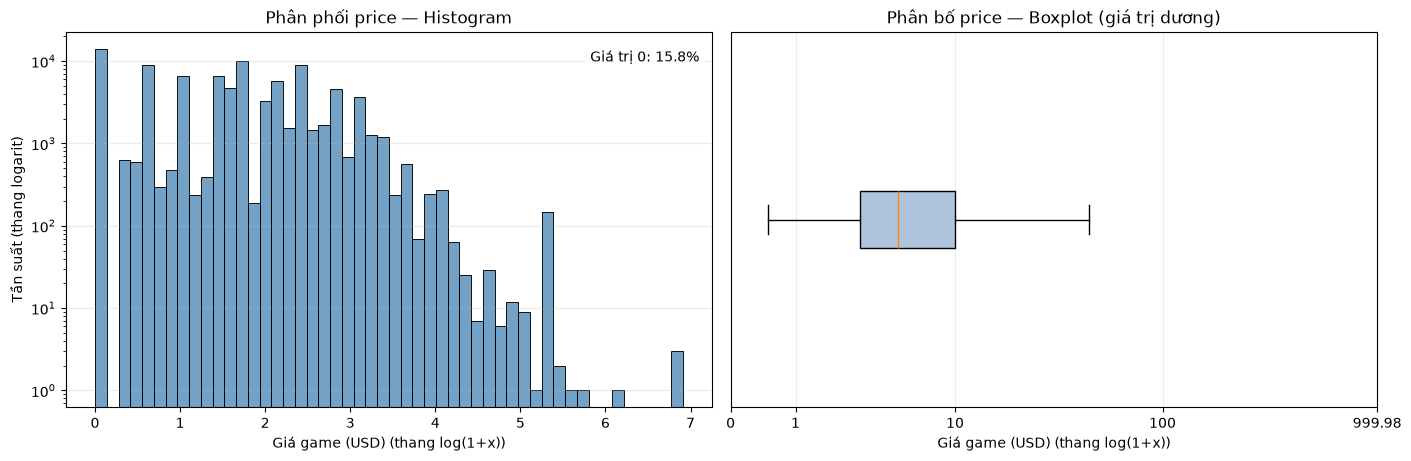

Đã lưu biểu đồ pct_pos_total tại: D:\Ki_7\LT\project\STEAM-GAME-PROJECT\reports\figures\distribution_pct_pos_total.png


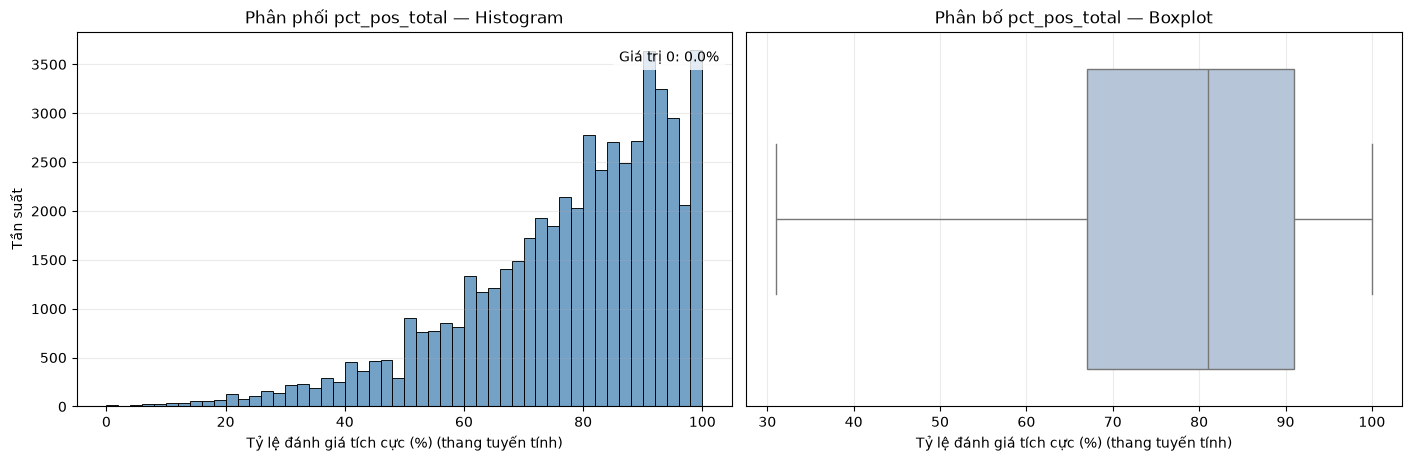

Đã lưu biểu đồ positive tại: D:\Ki_7\LT\project\STEAM-GAME-PROJECT\reports\figures\distribution_positive.png


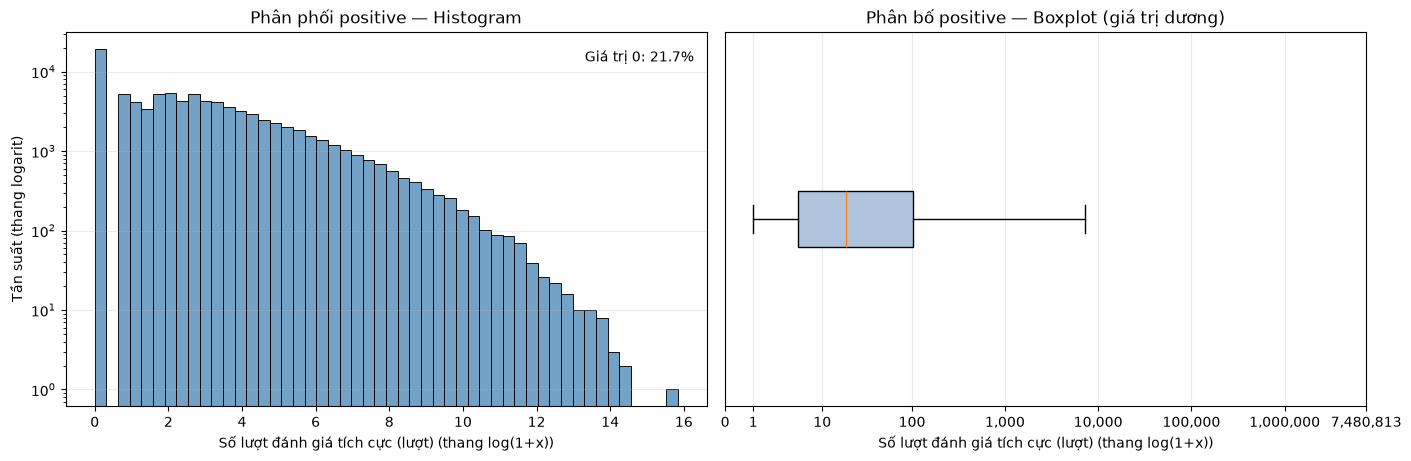

Đã lưu biểu đồ average_playtime_forever tại: D:\Ki_7\LT\project\STEAM-GAME-PROJECT\reports\figures\distribution_average_playtime_forever.png


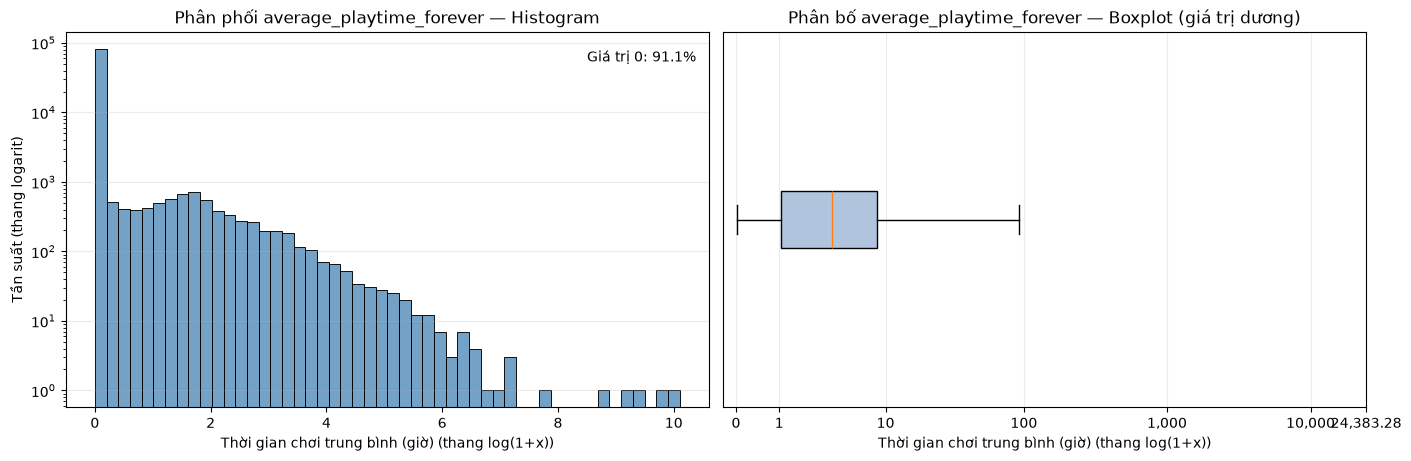

Đã lưu biểu đồ median_playtime_forever tại: D:\Ki_7\LT\project\STEAM-GAME-PROJECT\reports\figures\distribution_median_playtime_forever.png


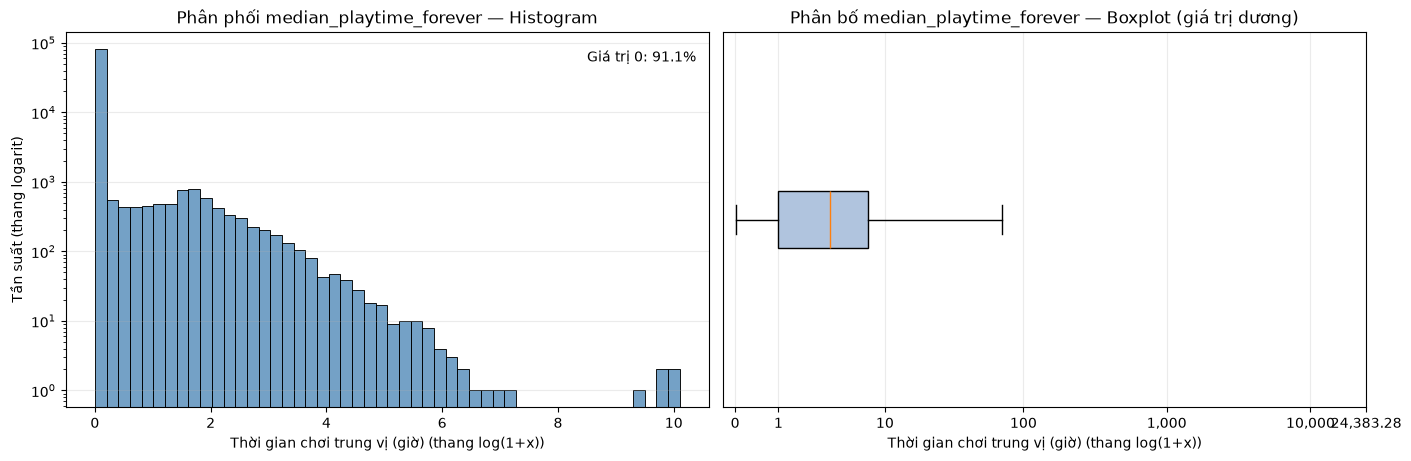

Đã lưu biểu đồ peak_ccu tại: D:\Ki_7\LT\project\STEAM-GAME-PROJECT\reports\figures\distribution_peak_ccu.png


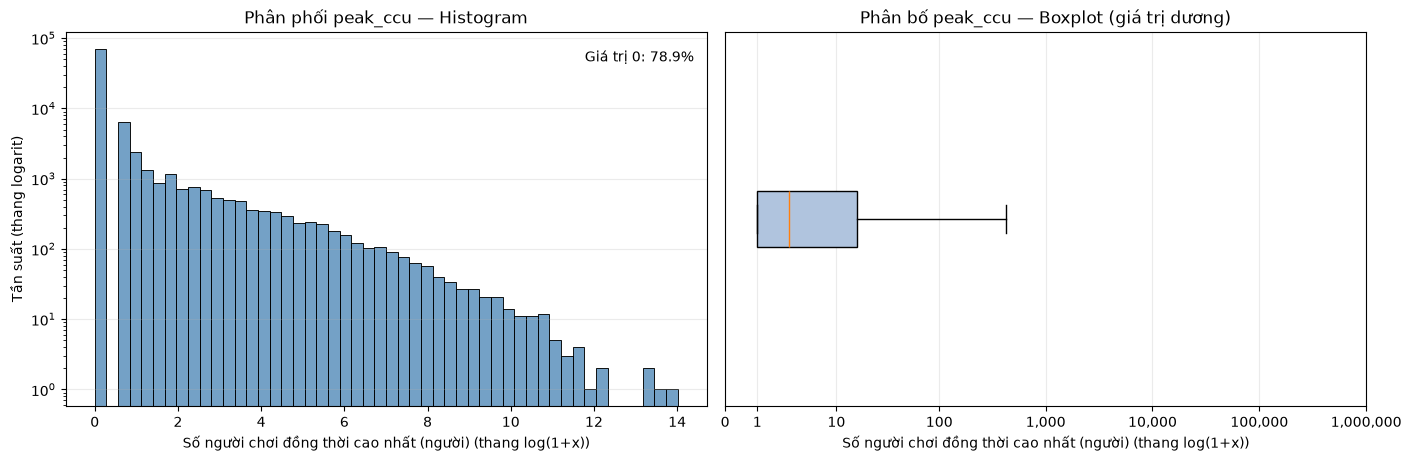

Đã lưu 6 hình phân phối riêng lẻ.
Độ lệch và mức độ phân tán của các thuộc tính được biểu diễn


,Trung vị,Độ lệch,Độ lệch chuẩn,Khoảng tứ phân vị (IQR)
Thuộc tính,,,,
price,4.99,20.72,13.33,9.0
pct_pos_total,81.00,-1.05,17.63,24.0
positive,10.00,156.81,31814.41,57.0
average_playtime_forever,0.00,165.64,113.58,0.0
median_playtime_forever,0.00,143.66,146.78,0.0
peak_ccu,0.00,153.31,5717.54,0.0


In [3]:
UNITS = {
    "price": "Giá game (USD)",
    "pct_pos_total": "Tỷ lệ đánh giá tích cực (%)",
    "metacritic_score": "Điểm Metacritic (điểm)",
    "positive": "Số lượt đánh giá tích cực (lượt)",
    "average_playtime_forever": "Thời gian chơi trung bình (giờ)",
    "median_playtime_forever": "Thời gian chơi trung vị (giờ)",
    "peak_ccu": "Số người chơi đồng thời cao nhất (người)",
}

distribution_rows = []
saved_distribution_figures = []
for column in available_distribution_columns:
    values = numeric_frame[column].dropna().copy()
    if "playtime" in column:
        values = values / 60
    if values.empty:
        continue

    q1_plot, q3_plot = values.quantile([0.25, 0.75])
    distribution_rows.append({
        "Thuộc tính": column,
        "Trung vị": values.median(),
        "Độ lệch": values.skew(),
        "Độ lệch chuẩn": values.std(),
        "Khoảng tứ phân vị (IQR)": q3_plot - q1_plot,
    })

    distribution_fig, (histogram_ax, boxplot_ax) = plt.subplots(
        1, 2, figsize=(14, 4.5), layout="constrained"
    )
    zero_rate = values.eq(0).mean() * 100
    use_log_scale = column != "pct_pos_total" and values.min() >= 0
    if use_log_scale:
        plot_values = np.log1p(values)
        max_value = values.max()
        tick_values = [0.0]
        if 0 < max_value < 1:
            tick_values.append(max_value)
        elif max_value >= 1:
            tick_values.extend(
                10.0 ** exponent
                for exponent in range(int(np.floor(np.log10(max_value))) + 1)
                if 10.0 ** exponent < max_value
            )
            if max_value / tick_values[-1] >= 2:
                tick_values.append(max_value)
        x_ticks = np.log1p(tick_values)
        x_tick_labels = [f"{value:,.2f}".rstrip("0").rstrip(".") for value in tick_values]
        scale_label = "thang log(1+x)"
    else:
        plot_values = values
        x_ticks = None
        x_tick_labels = None
        scale_label = "thang tuyến tính"

    sns.histplot(plot_values, bins=50, ax=histogram_ax, color="steelblue")
    if use_log_scale:
        histogram_ax.set_yscale("log")
    histogram_ax.set_title(f"Phân phối {column} — Histogram")
    histogram_ax.set_xlabel(f"{UNITS[column]} ({scale_label})")
    histogram_ax.set_ylabel("Tần suất (thang logarit)" if use_log_scale else "Tần suất")
    histogram_ax.grid(axis="y", alpha=0.25)
    histogram_ax.text(
        0.98, 0.95, f"Giá trị 0: {zero_rate:.1f}%",
        transform=histogram_ax.transAxes, ha="right", va="top",
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )

    if use_log_scale:
        positive_values = values[values > 0]
        if positive_values.empty:
            boxplot_ax.text(0.5, 0.5, "Không có giá trị dương", ha="center", va="center")
        else:
            boxplot_ax.boxplot(
                np.log1p(positive_values), orientation="horizontal", showfliers=False,
                patch_artist=True, boxprops={"facecolor": "lightsteelblue"},
            )
            boxplot_ax.set_xticks(x_ticks, labels=x_tick_labels)
    else:
        sns.boxplot(x=plot_values, ax=boxplot_ax, color="lightsteelblue", showfliers=False)
    boxplot_title = f"Phân bố {column} — Boxplot"
    if use_log_scale:
        boxplot_title += " (giá trị dương)"
    boxplot_ax.set_title(boxplot_title)
    boxplot_ax.set_xlabel(f"{UNITS[column]} ({scale_label})")
    boxplot_ax.set_yticks([])
    boxplot_ax.grid(axis="x", alpha=0.25)

    distribution_figure_path = FIGURES_DIR / f"distribution_{column}.png"
    distribution_fig.savefig(distribution_figure_path, dpi=200, bbox_inches="tight")
    saved_distribution_figures.append(distribution_figure_path)
    print(f"Đã lưu biểu đồ {column} tại: {distribution_figure_path}")
    plt.show()
    plt.close(distribution_fig)

print(f"Đã lưu {len(saved_distribution_figures)} hình phân phối riêng lẻ.")
distribution_summary = pd.DataFrame(distribution_rows).set_index("Thuộc tính")
print("Độ lệch và mức độ phân tán của các thuộc tính được biểu diễn")
display(distribution_summary.round(2))

**Nhận xét:** `price` có trung vị 4,99 USD (Q1 = 0,99; Q3 = 9,99), trong khi giá trị lớn nhất là 999,98 USD; phân phối lệch phải rõ (độ lệch 20,72). `positive` cũng lệch phải mạnh (độ lệch 156,81): trung vị 10, Q3 = 58, nhưng giá trị lớn nhất là 7.480.813 lượt. Hai thuộc tính thời gian chơi có 91,06% giá trị bằng 0; `peak_ccu` có 78,89% giá trị bằng 0. `pct_pos_total` có trung vị 81%, Q1 = 67%, Q3 = 91% và hơi lệch trái (độ lệch -1,05). Boxplot của các thuộc tính lệch chỉ trình bày giá trị dương; tỷ lệ giá trị 0 được ghi trên Histogram.

## 3.2.2.3. Phát hiện giá trị ngoại lai và so sánh IQR, Z-score

IQR sử dụng hai ngưỡng `Q1 − 1,5 × IQR` và `Q3 + 1,5 × IQR`; Z-score đánh dấu quan sát có `|Z| > 3`. Bảng so sánh số lượng và tỷ lệ của hai phương pháp. Không tự động loại bỏ các giá trị bị đánh dấu.

In [4]:
outlier_rows = []
for column in available_outlier_columns:
    values = numeric_frame[column].dropna()
    if values.empty:
        continue
    lower_quartile, upper_quartile = values.quantile([0.25, 0.75])
    interquartile_range = upper_quartile - lower_quartile
    lower_bound = lower_quartile - 1.5 * interquartile_range
    upper_bound = upper_quartile + 1.5 * interquartile_range
    iqr_mask = (values < lower_bound) | (values > upper_bound)

    standard_deviation = values.std(ddof=0)
    if standard_deviation == 0:
        z_score_mask = pd.Series(False, index=values.index)
    else:
        z_scores = (values - values.mean()) / standard_deviation
        z_score_mask = z_scores.abs() > 3

    outlier_rows.append({
        "Thuộc tính": column,
        "Số ngoại lai (IQR)": int(iqr_mask.sum()),
        "Tỷ lệ ngoại lai (IQR, %)": iqr_mask.mean() * 100,
        "Số ngoại lai (Z-score)": int(z_score_mask.sum()),
        "Tỷ lệ ngoại lai (Z-score, %)": z_score_mask.mean() * 100,
    })

outlier_comparison = pd.DataFrame(outlier_rows).set_index("Thuộc tính")
print("So sánh số lượng và tỷ lệ ngoại lai theo IQR và Z-score")
display(outlier_comparison.round(2))

So sánh số lượng và tỷ lệ ngoại lai theo IQR và Z-score


,Số ngoại lai (IQR),"Tỷ lệ ngoại lai (IQR, %)",Số ngoại lai (Z-score),"Tỷ lệ ngoại lai (Z-score, %)"
Thuộc tính,,,,
price,4146,4.63,823,0.92
positive,15039,16.78,186,0.21
negative,14344,16.01,138,0.15
recommendations,16737,18.68,226,0.25
average_playtime_forever,8010,8.94,33,0.04
median_playtime_forever,8010,8.94,14,0.02
peak_ccu,18920,21.11,68,0.08


**Nhận xét:** IQR đánh dấu nhiều giá trị hơn Z-score ở cả bảy thuộc tính trong bảng. `peak_ccu` có số lượng bị đánh dấu theo IQR cao nhất (18.920; 21,11%), trong khi Z-score đánh dấu 68 giá trị (0,08%). `recommendations`, hai thuộc tính thời gian chơi và `peak_ccu` có IQR bằng 0; vì vậy các giá trị dương bị IQR đánh dấu theo ngưỡng của phương pháp. Đây là cờ thống kê để xem xét, không phải kết luận dữ liệu sai; không loại bỏ tự động.

# 3.2.3. Phân tích dữ liệu thiếu

## 3.2.3.1. Tổng quan dữ liệu thiếu

Thống kê `NaN` trên toàn bộ các cột, sắp xếp theo tỷ lệ thiếu giảm dần.

In [5]:
missing_counts = df.isna().sum()
missing_rates = df.isna().mean() * 100
missing_overview = pd.DataFrame({
    "Số lượng giá trị thiếu": missing_counts,
    "Tỷ lệ thiếu (%)": missing_rates,
}).sort_values("Tỷ lệ thiếu (%)", ascending=False)
missing_overview.index.name = "Thuộc tính"
print("Tổng quan giá trị NaN trong toàn bộ dữ liệu")
display(missing_overview.round(2))

Tổng quan giá trị NaN trong toàn bộ dữ liệu


,Số lượng giá trị thiếu,Tỷ lệ thiếu (%)
Thuộc tính,,
Unnamed: 0,0,0.0
appid,0,0.0
name,0,0.0
release_date,0,0.0
required_age,0,0.0
price,0,0.0
dlc_count,0,0.0
achievements,0,0.0
recommendations,0,0.0


**Nhận xét:** Dữ liệu hiện có 89.618 dòng và 29 cột; bảng cho thấy không có giá trị `NaN` thực tế ở các cột này.

## 3.2.3.2. Trực quan hóa dữ liệu thiếu

Missing Matrix được sử dụng để quan sát vị trí và mẫu hình của `NaN`. Nếu không có giá trị `NaN`, ma trận không bổ sung thông tin và chỉ được ghi nhận bằng thông báo.

In [6]:
if df.isna().to_numpy().any():
    visualization_sample = df
    if len(df) > 5000:
        visualization_sample = df.sample(n=5000, random_state=42)
    missing_fig = plt.figure(figsize=(14, 5))
    msno.matrix(visualization_sample, ax=plt.gca(), sparkline=False, fontsize=9)
    plt.title("Ma trận vị trí dữ liệu thiếu (NaN)", pad=16)
    plt.xlabel("Thuộc tính")
    plt.ylabel("Bản ghi")
    plt.tight_layout()
    missing_matrix_path = FIGURES_DIR / "missing_data_matrix.png"
    missing_fig.savefig(missing_matrix_path, dpi=200, bbox_inches="tight")
    print(f"Đã lưu Missing Matrix tại: {missing_matrix_path}")
    plt.show()

**Nhận xét:** Không có `NaN` nên Missing Matrix không được tạo. Bảng tổng quan vẫn bao gồm toàn bộ 29 cột hiện có.

## 3.2.3.3. Kiểm tra giá trị thiếu được mã hóa đặc biệt

Bảng phân biệt `NaN` với các mã số được quy ước là thiếu. Chỉ các mã đặc biệt đã xác định mới được xem là thiếu; giá trị `0` khác vẫn có thể hợp lệ.

In [7]:
semantic_missing_rows = []
for column, (special_value, meaning) in available_special_missing.items():
    values = pd.to_numeric(df[column], errors="coerce")
    special_count = int(values.eq(special_value).sum())
    semantic_missing_rows.append({
        "Thuộc tính": column,
        "Giá trị đặc biệt": special_value,
        "Ý nghĩa": meaning,
        "Số lượng": special_count,
        "Tỷ lệ (%)": special_count / len(df) * 100 if len(df) else 0,
        "Số NaN thực tế": int(df[column].isna().sum()),
    })

semantic_missing_summary = pd.DataFrame(semantic_missing_rows)
if not semantic_missing_summary.empty:
    semantic_missing_summary = semantic_missing_summary.set_index("Thuộc tính")
    print("Thống kê các mã thiếu đặc biệt")
    display(semantic_missing_summary.round(2))

Thống kê các mã thiếu đặc biệt


,Giá trị đặc biệt,Ý nghĩa,Số lượng,Tỷ lệ (%),Số NaN thực tế
Thuộc tính,,,,,
pct_pos_total,-1,Không đủ 10 lượt đánh giá,36419,40.64,0
num_reviews_total,-1,Không đủ 10 lượt đánh giá,36419,40.64,0


**Nhận xét:** Hai cột `pct_pos_total` và `num_reviews_total` cùng có mã `-1` ở 36.419 dòng (40,64% mỗi cột); ý nghĩa của mã này trong dữ liệu là không đủ 10 lượt đánh giá. Mã `-1` được phân biệt với `NaN`; các giá trị `0` không được mặc định xem là thiếu.

## 3.2.3.4. Phân tích mẫu hình dữ liệu thiếu

Các mẫu hình được tổng hợp từ `NaN` thực tế và mã thiếu đặc biệt đã xác định. Bảng cho biết các thiếu hụt có xuất hiện đồng thời trên cùng bản ghi hay không.

In [8]:
missing_indicators = df.isna().copy()
for column, (special_value, _) in available_special_missing.items():
    values = pd.to_numeric(df[column], errors="coerce")
    missing_indicators[f"{column} = {special_value}"] = values.eq(special_value)

variable_missing_columns = missing_indicators.columns[missing_indicators.any()].tolist()
if variable_missing_columns:
    row_patterns = missing_indicators[variable_missing_columns].apply(
        lambda row: ", ".join(row.index[row]), axis=1
    )
    rows_with_missing = row_patterns[row_patterns.ne("")]
    pattern_summary = (
        rows_with_missing.value_counts()
        .rename_axis("Mẫu hình thiếu")
        .rename("Số dòng")
        .to_frame()
    )
    pattern_summary["Tỷ lệ trên toàn bộ dữ liệu (%)"] = pattern_summary["Số dòng"] / len(df) * 100
    print("Các mẫu hình thiếu đồng thời, sắp xếp theo số dòng")
    display(pattern_summary.head(15).round(2))

else:
    print("Không có mẫu hình thiếu để hiển thị.")

Các mẫu hình thiếu đồng thời, sắp xếp theo số dòng


,Số dòng,Tỷ lệ trên toàn bộ dữ liệu (%)
Mẫu hình thiếu,,
"pct_pos_total = -1, num_reviews_total = -1",36419,40.64


**Nhận xét:** Mẫu hình quan sát được là `pct_pos_total = -1` và `num_reviews_total = -1` xuất hiện đồng thời trên 36.419 dòng (40,64% dữ liệu). 53.199 dòng còn lại không mang hai mã này. Không có `NaN` thực tế; ở bước tiền xử lý cần phân biệt mã `-1` với dữ liệu thiếu dạng `NaN`.